In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("train.csv", parse_dates=["date"])

print(df.head())
print(df.shape)
print(df.isna().sum())
print(df["date"].min(), df["date"].max())
print(df["store"].nunique(), df["item"].nunique())

Matplotlib is building the font cache; this may take a moment.


        date  store  item  sales
0 2013-01-01      1     1     13
1 2013-01-02      1     1     11
2 2013-01-03      1     1     14
3 2013-01-04      1     1     13
4 2013-01-05      1     1     10
(913000, 4)
date     0
store    0
item     0
sales    0
dtype: int64
2013-01-01 00:00:00 2017-12-31 00:00:00
10 50


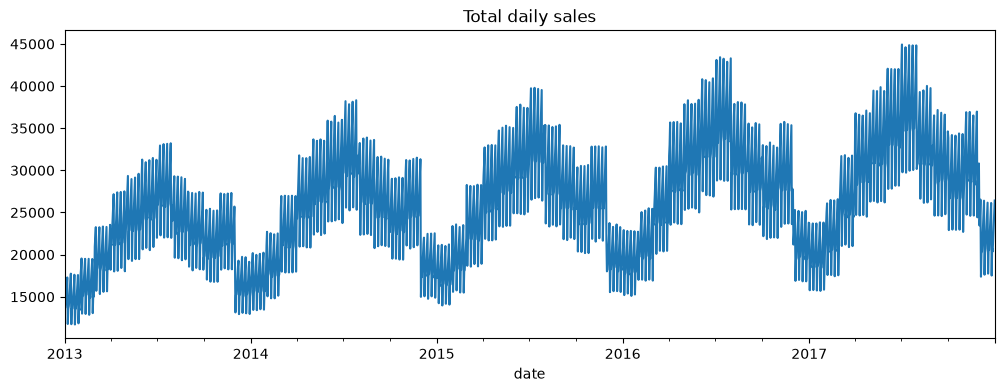

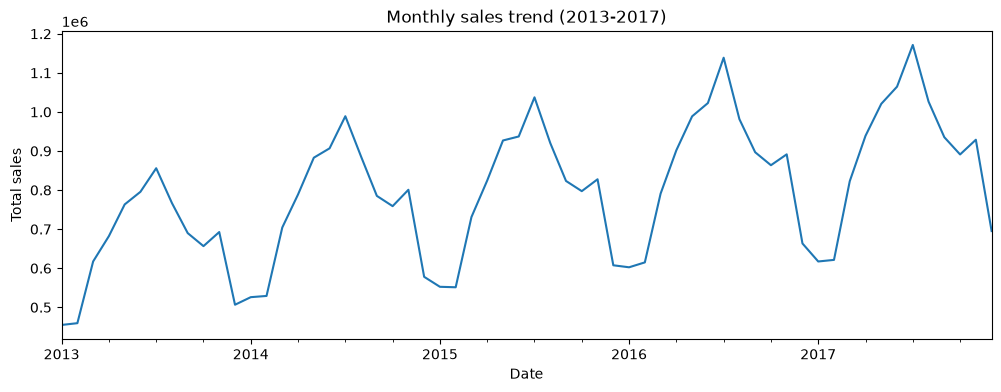

In [2]:
daily = df.groupby("date")["sales"].sum()
daily.plot(figsize=(12, 4), title="Total daily sales")
plt.show()

monthly_sales = df.groupby(df["date"].dt.to_period("M"))["sales"].sum()
monthly_sales.index = monthly_sales.index.to_timestamp()
monthly_sales.plot(figsize=(12, 4), title="Monthly sales trend (2013-2017)")
plt.ylabel("Total sales")
plt.xlabel("Date")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_10076\4186570932.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = df["date"].dt.dayofweek


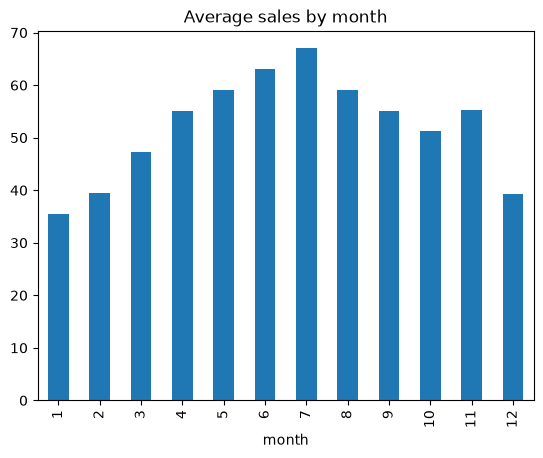

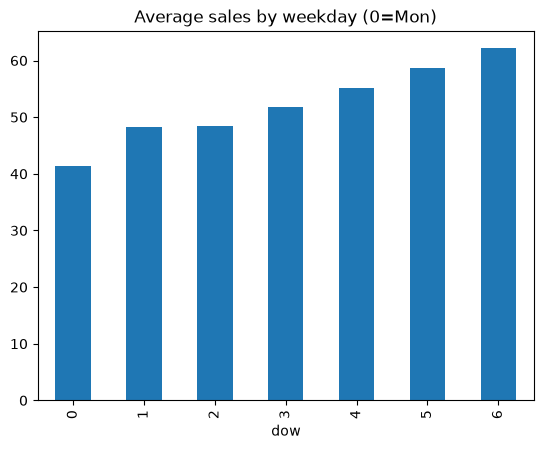

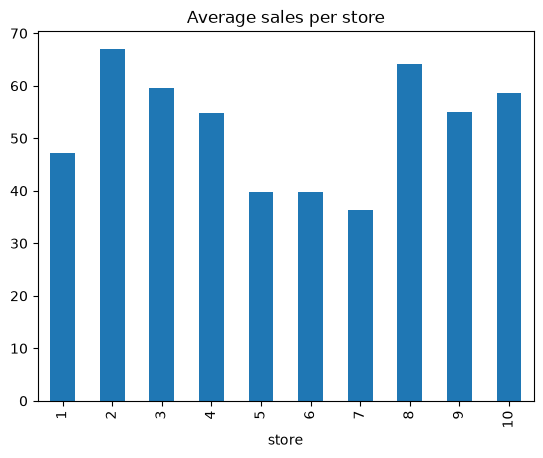

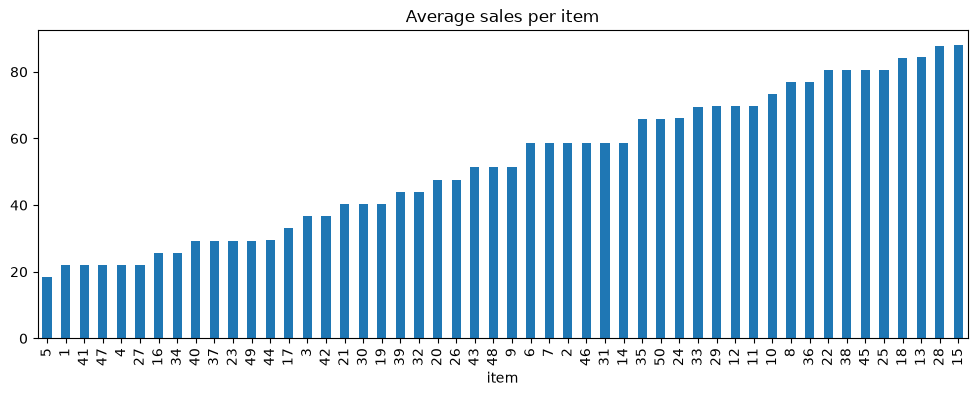

In [3]:
df["month"] = df["date"].dt.month
df["dow"] = df["date"].dt.dayofweek

df.groupby("month")["sales"].mean().plot(kind="bar", title="Average sales by month")
plt.show()

df.groupby("dow")["sales"].mean().plot(kind="bar", title="Average sales by weekday (0=Mon)")
plt.show()

df.groupby("store")["sales"].mean().plot(kind="bar", title="Average sales per store")
plt.show()

df.groupby("item")["sales"].mean().sort_values().plot(
    kind="bar", figsize=(12, 4), title="Average sales per item")
plt.show()

- Strong yearly seasonality. Sales rise every year from January to a peak around July, then fall toward year end. Average sales are lowest in January (about 36) and highest in July (about 67).
- Upward trend. The seasonal peaks get higher each year (roughly 0.85M in 2013 to about 1.17M in 2017).
- Weekly pattern. Monday is the lowest day (about 41) and sales climb through the week to Sunday (about 62).
- Stores and items differ a lot. Store 2 sells the most (about 67) and store 7 the least (about 36). Item averages range from about 19 to about 88.